## Daily Delhi Climate: Time Series Forecasting of Mean Temperature (SARIMAX with Fourier Terms)

## 1. Project Overview
### What it does: The project uses 4 years of daily Delhi temperature data (2013–2017) to build a forecasting model. It handles the yearly seasonal cycle with Fourier terms and an ARIMA (3,1,3) model, after a log transform to even out the data
### How well it works: On unseen test data, the model's average error is 6.83% (RMSE 2.34°C), better than the "same day last year" baseline at 9.88%. It then forecasts the next 365 days with 95% confidence ranges and saves the results as a CSV and charts

## 2. Project Objectives

## Main Objective

### Build a model that forecasts Delhi's daily mean temperature for the next 365 days

## Specific Objectives

### 1) Prepare the data: Load the daily data, fix the date format and set a daily index
### 2) Understand the pattern: Break the temperature into trend, yearly seasonality and noise, and test if the data is stationary
### 3) Handle seasonality: Use Fourier terms to capture the yearly temperature cycle
### 4) Find the best model: Use auto_arima to pick the best ARIMA settings, which gave (3,1,3)
### 5) Check model quality: Review residual plots to see if the errors look reasonable
### 6) Test on unseen data: Train on 80% of the data and test on the last 20%, measuring MAPE and RMSE 
### 7) Compare with a baseline: Check that the model beats the "same day last year" method (6.83% vs 9.88% MAPE)
### 8) Forecast the future: Retrain on all data and predict the next 365 days with 95% confidence ranges
### 9) Save the results: Export the forecast as a CSV and the charts as images

## 3. Dataset Description

### 1) Name: DailyDelhiClimateTrain.csv
### 2) Source type: Daily weather records for Delhi, India
### 3) Time span: 01-01-2013 to 01-01-2017 (about 4 years)
### 4) Size: 1,462 rows, one per day
### 5) Frequency: Daily, with no gaps (the notebook sets the index to daily)
### 6) Date format: Day-month-year (e.g., 01-01-2013)
### 7) Use in project: Only temperature is used for modeling. The other columns are loaded but not used
### 8) Split used: 1,169 days for training (to 14-Mar-2016), 293 days for testing

## 4. Dataset Features

| Feature | Description | Type | Used in Model? |
|---|---|---|---|
| date | The calendar day. Used as the index. | Date | Index |
| meantemp | Average daily temperature in °C | Number | Target (original) |
| humidity | Average daily humidity | Number | No |
| wind_speed | Average daily wind speed | Number | No |
| meanpressure | Average daily air pressure | Number | No |
| meantemp_log | Log10 of meantemp | Number | Yes, model trains on this |
| sin1–sin3, cos1–cos3 | Six Fourier columns for the yearly cycle | Number | Yes, extra inputs |

## 5. Project Overflow

## Step 1: Import Libraries

### Loads all the tools needed for data handling, charts, time series models and error scoring

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
from pmdarima import auto_arima
import warnings
warnings.filterwarnings("ignore")

## Step 2: Install pmdarima

### Installs the package that automatically finds the best model settings

In [40]:
pip install pmdarima

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## Step 3: Load Data

### Reads the CSV file, fixes the date format (day-month-year), and makes date the index, sorted in order

In [53]:
import os
os.chdir(r"C:\Users\HP\Desktop\Python for Data Science\Machine Learning\Time Series Fourcasting")

data = pd.read_csv(r"C:\Users\HP\Desktop\Python for Data Science\Machine Learning\Time Series Fourcasting\DailyDelhiClimateTrain.csv")
data["date"] = pd.to_datetime(data["date"], format="%d-%m-%Y")
data = data.set_index("date").sort_index()
data.head()

,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


## Step 4: Set Daily Frequency

### Tells the model that each row is one day, with no gaps

In [54]:
# Explicitly set the frequency to Daily ('D')

data.index.freq = "D"

## Step 5: Log Transform

### Applies log10 to temperature so the ups and downs are more even across the series

In [55]:
# Apply log10 transformation

data["meantemp_log"] = np.log10(data["meantemp"])

## Step 6: Seasonal Decomposition

### Splits the data into trend, yearly pattern and leftover noise, then saves the plot as a PDF

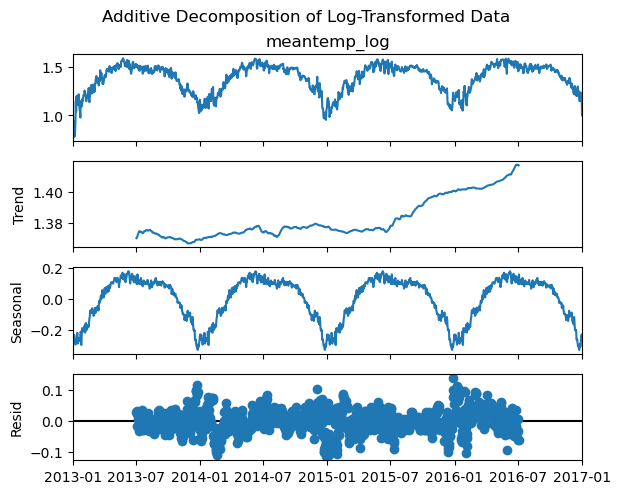

In [56]:
# Decomposition on log-transformed data requires an 'additive' model

decomposition = seasonal_decompose(data['meantemp_log'], model='additive',period=365)
decomposition.plot()
plt.suptitle('Additive Decomposition of Log-Transformed Data', y=1.02)
plt.savefig("delhi_decomposition.pdf", bbox_inches="tight")   
plt.show()

## Step 7: Stationarity Test (ADF)

### Checks if the data is stable over time; the p-value is 0.006, so the test calls it stationary

In [57]:
def check_stationarity(timeseries):
    print("Results of Dickey-Fuller Test:")
    dftest = adfuller(timeseries, autolag="AIC")
    dfoutput = pd.Series(dftest[0:4], index=["Test Statistic", "p-value", "#Lags Used", "Number of Observations Used"])
    for key, value in dftest[4].items():
        dfoutput[f"Critical Value ({key})"] = value
    print(dfoutput)
    if dftest[1] <= 0.05:
        print("Strong evidence against the null hypothesis: Data is stationary.")
    else:
        print("Weak evidence against the null hypothesis: Data is non-stationary (needs differencing).")

check_stationarity(data["meantemp_log"])

Results of Dickey-Fuller Test:
Test Statistic                   -3.586512
p-value                           0.006024
#Lags Used                        5.000000
Number of Observations Used    1456.000000
Critical Value (1%)              -3.434849
Critical Value (5%)              -2.863527
Critical Value (10%)             -2.567828
dtype: float64
Strong evidence against the null hypothesis: Data is stationary.


## Step 8: Train/Test Split

### Uses the first 80% of days (1,169, up to 14-Mar-2016) for training and the last 20% (293 days) for testing

In [58]:
split_point = int(len(data) * 0.8)
train = data.iloc[:split_point]
test = data.iloc[split_point:]
print("Train:", len(train), "days |", train.index[0].date(), "to", train.index[-1].date())
print("Test :", len(test), "days |", test.index[0].date(), "to", test.index[-1].date())

Train: 1169 days | 2013-01-01 to 2016-03-14
Test : 293 days | 2016-03-15 to 2017-01-01


## Step 9: Fourier Features

### Creates 3 pairs of sine and cosine columns to teach the model the yearly seasonal cycle

In [59]:
K = 3
ORIGIN = data.index[0]   # same time origin for train, test and future dates

def fourier(index, K=K, period=365.25):
    t = (index - ORIGIN).days.values
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / period)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=index)

X_train = fourier(train.index)
X_test = fourier(test.index)

## Step 10: Auto ARIMA

### Searches many settings and picks the best model: ARIMA (3,1,3) with no trend term

In [60]:
model_auto = auto_arima(
    train["meantemp_log"], X=X_train,
    seasonal=False,
    start_p=1, start_q=1, max_p=3, max_q=3,
    d=None,
    trace=True, error_action="ignore",
    suppress_warnings=True, stepwise=True
)
print(model_auto.summary())

optimal_order = model_auto.order
# SARIMAX has no intercept by default, so match what auto_arima chose
use_trend = "c" if (model_auto.with_intercept and optimal_order[1] == 0) else None
print("Order:", optimal_order, "| trend:", use_trend)

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-4691.143, Time=2.69 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-4590.604, Time=0.35 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-4623.453, Time=0.31 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-4632.121, Time=1.85 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-4592.596, Time=0.94 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-4673.852, Time=2.51 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-4680.942, Time=2.64 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-4644.981, Time=1.51 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=-4631.141, Time=0.98 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-4693.967, Time=2.72 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=2.92 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=-4678.514, Time=2.86 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=-4662.604, Time=2.91 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=-4662.002, Time=2.74 sec
 ARIMA(3,1,3)(0,0,0)[0] i

## Step 11: Residual Diagnostics

### Fits the model on training data and plots the errors to check whether the model is reasonable

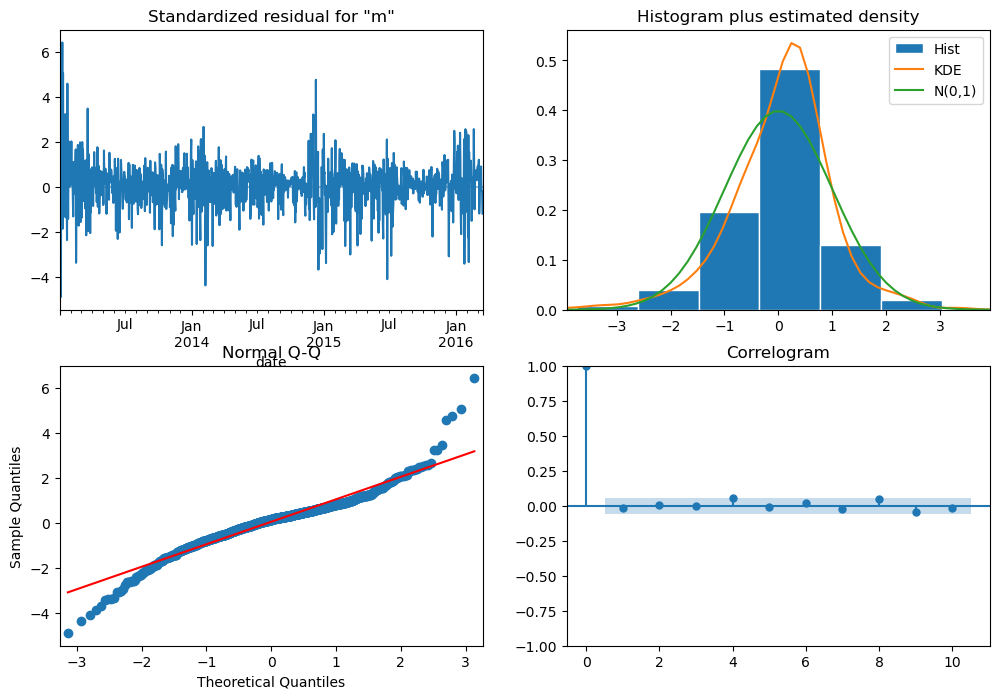

In [61]:
# Plot residual diagnostics

model = SARIMAX(train["meantemp_log"], exog=X_train, order=optimal_order, trend=use_trend)
fitted_model = model.fit(disp=False)
fitted_model.plot_diagnostics(figsize=(12, 8))
plt.show()

## Step 12: Model Evaluation

### Scores the test predictions: MAPE 6.83% and RMSE 2.34, against 9.88% and 3.53 for the "same day last year" baseline

In [62]:
# Evaluation Metrics

predictions_log = fitted_model.predict(start=test.index[0], end=test.index[-1], exog=X_test)
predictions_original = np.power(10, predictions_log)

mape = mean_absolute_percentage_error(test["meantemp"], predictions_original) * 100
rmse = np.sqrt(mean_squared_error(test["meantemp"], predictions_original))

# Baseline: temperature on the same day one year earlier
naive = data["meantemp"].shift(365).loc[test.index]
naive_mape = mean_absolute_percentage_error(test["meantemp"], naive) * 100
naive_rmse = np.sqrt(mean_squared_error(test["meantemp"], naive))

print(f"Model   -> MAPE: {mape:.2f}%  RMSE: {rmse:.2f}")
print(f"Naive   -> MAPE: {naive_mape:.2f}%  RMSE: {naive_rmse:.2f}")

Model   -> MAPE: 6.83%  RMSE: 2.34
Naive   -> MAPE: 9.88%  RMSE: 3.53


## Step 13: Plot Predictions

### Draws training data, actual test data and predicted values on one chart and saves it as an image

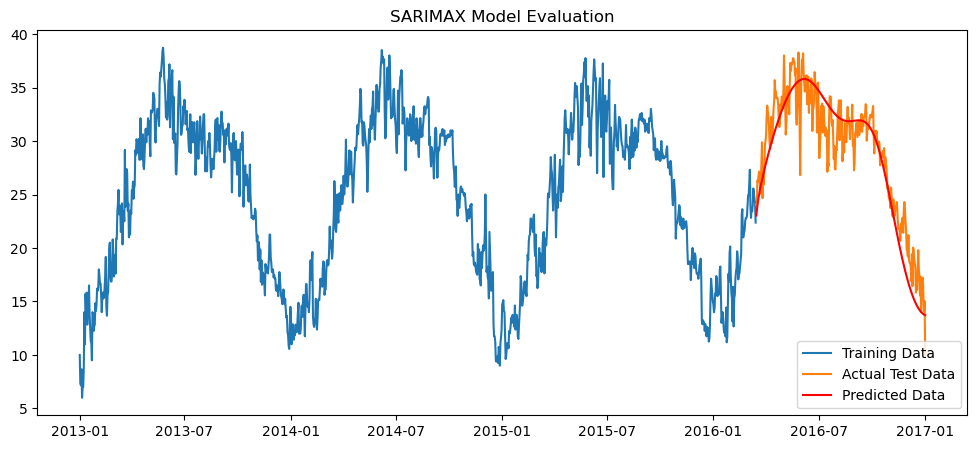

In [63]:
# Plot Train, Test, and Predictions

plt.figure(figsize=(12, 5))
plt.plot(train.index, train["meantemp"], label="Training Data")
plt.plot(test.index, test["meantemp"], label="Actual Test Data")
plt.plot(test.index, predictions_original, label="Predicted Data", color="red")
plt.legend()
plt.title("SARIMAX Model Evaluation")
plt.savefig("delhi_model_evaluation.jpg", bbox_inches="tight")   # save BEFORE show
plt.show()

## Step 14: Final Model

### Retrains the same model on the full dataset so it uses all available data

In [64]:
final_model = SARIMAX(data["meantemp_log"], exog=fourier(data.index), order=optimal_order, trend=use_trend)
final_fitted_model = final_model.fit(disp=False)

## Step 15: Future Forecast

### Predicts the next 365 days with 95% lower and upper bounds, converted back to °C

In [65]:
# Daily data: this is a number of DAYS (365 = 1 year). Longer horizons give wider, less reliable bands.
forecast_periods = 365

future_index = pd.date_range(data.index[-1] + pd.Timedelta(days=1), periods=forecast_periods, freq="D")
forecast_log = final_fitted_model.get_forecast(steps=forecast_periods, exog=fourier(future_index))

forecast_mean = np.power(10, forecast_log.predicted_mean)
conf_int_log = forecast_log.conf_int()
lower_bounds = np.power(10, conf_int_log.iloc[:, 0])
upper_bounds = np.power(10, conf_int_log.iloc[:, 1])

print(forecast_mean.head())
print("Forecast index type:", type(forecast_mean.index).__name__)

2017-01-02    11.257739
2017-01-03    11.682792
2017-01-04    12.433949
2017-01-05    12.868440
2017-01-06    13.091490
Freq: D, Name: predicted_mean, dtype: float64
Forecast index type: DatetimeIndex


## Step 16: Forecast Plot

### Shows history, forecast and confidence band on one chart and saves it as a PNG

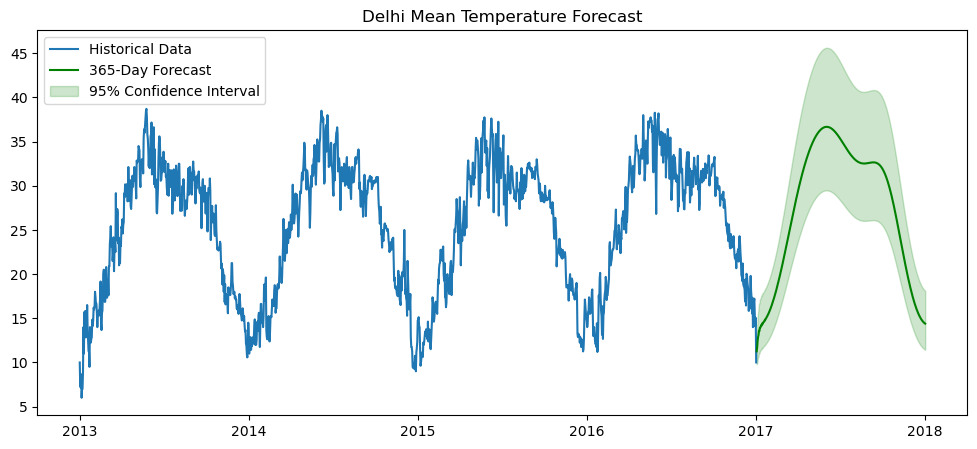

In [66]:
plt.figure(figsize=(12, 5))
plt.plot(data.index, data["meantemp"], label="Historical Data")
plt.plot(forecast_mean.index, forecast_mean, label=f"{forecast_periods}-Day Forecast", color="green")
plt.fill_between(forecast_mean.index, lower_bounds, upper_bounds, color="green", alpha=0.2, label="95% Confidence Interval")
plt.title("Delhi Mean Temperature Forecast")
plt.legend()
plt.savefig("delhi_final_forecast.png", bbox_inches="tight")
plt.show()

## Step 17: Export Forecast

### Saves the forecast and its bounds to "delhi_temperature_forecast.csv"

In [67]:
forecast_df = pd.DataFrame({"Forecast": forecast_mean, "Lower_CI": lower_bounds, "Upper_CI": upper_bounds})
forecast_df.to_csv("delhi_temperature_forecast.csv")
forecast_df.head()

,Forecast,Lower_CI,Upper_CI
2017-01-02,11.257739,9.802992,12.928368
2017-01-03,11.682792,9.856410,13.847600
2017-01-04,12.433949,10.302492,15.006378
2017-01-05,12.868440,10.569586,15.667288
2017-01-06,13.091490,10.696744,16.022362


### 6) Project Summary

#### 1) Import Libraries
#### 2)Install pmdarima
#### 3)Load Data
#### 4)Set Daily Frequency
#### 5)Log Transformation
#### 6)Seasonal Decomposition
#### 7)Stationarity Test (ADF)
#### 8)Train/Test Split
#### 9)Fourier Features
#### 10)Auto ARIMA Model Selection
#### 11)Residual Diagnostics
#### 12)Model Evaluation
#### 13)Plot Predictions
#### 14)Final Model Training
#### 15)Future Forecast (365 Days)
#### 16)Forecast Plot
#### 17)Export Forecast to CSV